# Лабораторная работа №10: Эффективный fine-tuning VLM с помощью Unsloth

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Повторить SFT на том же датасете через Unsloth.
- Сравнить LoRA rank и accumulation короткими runs.
- Построить quality-time-memory benchmark.


## Теоретическая часть

Эта работа оценивает не новый task, а efficiency: wall-clock, peak VRAM, throughput и качество при близких hyperparameters. Ускорение без эквивалентного evaluation не является результатом.


### Математическая постановка

Throughput $=N_{tokens}/T$, peak memory берётся из `torch.cuda.max_memory_allocated()`. Полезно строить Pareto frontier по quality, time и memory.


### Материалы

- [Unsloth docs](https://docs.unsloth.ai/)
- [PEFT](https://huggingface.co/docs/peft/index)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Тот же manifest и та же Qwen2.5-VL, что в работе 9. В Colab требуется совместимая пара версий Unsloth и TRL; зафиксируйте версии и аппаратное обеспечение. `FAST_DEV_RUN=True` всё равно запускает обучение, но только для smoke. Отсутствующие данные или GPU приводят к явной ошибке, а не к демонстрационному benchmark.

In [1]:
# ШИМ: utf-8 для pathlib + разовая перекодировка старых файлов (как в лабе 9)
import pathlib

def _install_utf8_shim():
    if getattr(pathlib.Path.write_text, "_utf8_shim", False):
        return
    _wt, _rt = pathlib.Path.write_text, pathlib.Path.read_text
    def write_text(self, data, *args, **kwargs):
        kwargs.setdefault("encoding", "utf-8")
        return _wt(self, data, *args, **kwargs)
    def read_text(self, *args, **kwargs):
        kwargs.setdefault("encoding", "utf-8")
        return _rt(self, *args, **kwargs)
    write_text._utf8_shim = read_text._utf8_shim = True
    pathlib.Path.write_text, pathlib.Path.read_text = write_text, read_text

_install_utf8_shim()

def _recode(p: pathlib.Path):
    try:
        p.read_text(encoding="utf-8")
    except UnicodeDecodeError:
        t = p.read_text(encoding="cp1251")
        p.write_text(t, encoding="utf-8")
        print("перекодирован в utf-8:", p)

for _pat in ("data/lab9/manifest*.jsonl", "data/lab9/ATTRIBUTION.md"):
    for _p in pathlib.Path().glob(_pat):
        _recode(_p)
print("utf-8 shim установлен")

utf-8 shim установлен


In [2]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))
from pathlib import Path
import json, hashlib
from datasets import load_dataset

SCIENCEQA_ID = 'derek-thomas/ScienceQA'
SCIENCEQA_REVISION = 'f18b0a70359ebfb41f658fd564208d0355b013f4'

def prepare_scienceqa(directory, smoke=False):
    """Fixed official splits, image-level deduplication, explicitly defined shifts."""
    directory = Path(directory).resolve(); directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ('manifest-smoke.jsonl' if smoke else 'manifest.jsonl')
    limits = {'train': 8 if smoke else 512, 'validation': 4 if smoke else 64,
              'id_test': 4 if smoke else 64, 'ood_test': 4 if smoke else 64,
              'general_test': 4 if smoke else 64}
    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text().splitlines()]
        if all(Path(r['image']).is_file() for r in records) and all(sum(r['split']==s for r in records)==n for s,n in limits.items()):
            return manifest
    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ('train', 'validation', 'test'):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split=official, streaming=True)
        for index, row in enumerate(data):
            image = row['image']
            if image is None: continue
            if official != 'test':
                if row['subject'] != 'natural science' or int(row['grade'].removeprefix('grade')) > 6: continue
                split = official
            elif row['subject'] != 'natural science': split = 'general_test'
            elif int(row['grade'].removeprefix('grade')) > 6: split = 'ood_test'
            else: split = 'id_test'
            if counts[split] >= limits[split]: continue
            image = image.convert('RGB')
            digest = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = directory / f'{digest}.png'; image.save(path)
            answer = int(row['answer']); choices = row['choices']
            question = row['question']+'\n'+'\n'.join(f'{chr(65+i)}. {v}' for i,v in enumerate(choices))+'\nReturn only the letter of the correct option.'
            records.append({'id': f'scienceqa-{official}-{index}', 'split': split,
                            'image': str(path), 'question': question, 'answer': chr(65+answer),
                            'choices': choices, 'answer_index': answer, 'label_type': 'multiple_choice',
                            'license': 'MIT (code license, lupantech/ScienceQA)',
                            'source_url': f'https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}',
                            'subject':row['subject'], 'grade':row['grade'], 'image_sha256':digest})
            counts[split] += 1
            required = [official] if official != 'test' else ['id_test','ood_test','general_test']
            if all(counts[s] == limits[s] for s in required): break
    if counts != limits: raise RuntimeError(f'Insufficient licensed image examples: {counts}; expected {limits}')
    manifest.write_text('\n'.join(json.dumps(r,ensure_ascii=False) for r in records)+'\n')
    (directory/'ATTRIBUTION.md').write_text('ScienceQA — Lu et al., NeurIPS 2022. Dataset distribution: '+SCIENCEQA_ID+'\nRevision: '+SCIENCEQA_REVISION+'\nDataset-card license: CC-BY-SA-4.0, https://creativecommons.org/licenses/by-sa/4.0/\nOriginal project: https://scienceqa.github.io/\nImage subsets and manifests retain attribution; downloaded images are not committed to this course.\nID: natural science grades 1–6; OOD: natural science grades 7–12; general: other subjects. This is an operational shift, not a claim of universal model ability.\n')
    return manifest


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Одинаковые данные для сравнения

*Вес: 1 балл.*

**Постановка.** Загрузите ту же фиксированную ScienceQA-подвыборку через prepare_scienceqa, что в работе 09. Для сравнения библиотек нельзя менять наборы, вопросы или разбиения.

**Результат.** Манифест и изображения.

**Критерий принятия.** ID/хеши записей совпадают с протоколом 09; train и test не пересекаются.


In [3]:
# ЭТАП 1 — тот же манифест и те же картинки, что в лабе 9
import json
from pathlib import Path

def _find_data_dir():
    cands = [Path("data/lab9"), Path("../lab9/data/lab9"), Path("lab9/data/lab9"), Path("../data/lab9")]
    for c in cands:
        if (c / "manifest.jsonl").is_file():
            return c
    raise RuntimeError("Не нашёл data/lab9 с манифестом лабы 9. Запусти lab10 из папки курса или поправь список путей выше.")

DATA_DIR = _find_data_dir()

if FAST_DEV_RUN:
    # smoke-манифест строим из полного БЕЗ СЕТИ (те же файлы картинок, те же хеши)
    smoke_path = DATA_DIR / "manifest-smoke.jsonl"
    if not smoke_path.exists():
        full = [json.loads(s) for s in (DATA_DIR / "manifest.jsonl").read_text(encoding="utf-8").splitlines() if s.strip()]
        limits = {"train": 8, "validation": 4, "id_test": 4, "ood_test": 4, "general_test": 4}
        picked, cnt = [], dict.fromkeys(limits, 0)
        for r in full:
            if cnt[r["split"]] < limits[r["split"]]:
                picked.append(r); cnt[r["split"]] += 1
        smoke_path.write_text("\n".join(json.dumps(r, ensure_ascii=False) for r in picked) + "\n", encoding="utf-8")
        print("собран smoke-манифест из полного (офлайн):", smoke_path)

manifest = prepare_scienceqa(DATA_DIR, smoke=FAST_DEV_RUN)  # кэш-проверка, сеть не нужна
records = [json.loads(s) for s in manifest.read_text(encoding="utf-8").splitlines() if s.strip()]
counts = {}
for r in records:
    counts[r["split"]] = counts.get(r["split"], 0) + 1
print("манифест:", manifest)
print("записей:", len(records), "| по сплитам:", counts)

_expect = {"train": 8, "validation": 4, "id_test": 4, "ood_test": 4, "general_test": 4} if FAST_DEV_RUN \
          else {"train": 512, "validation": 64, "id_test": 64, "ood_test": 64, "general_test": 64}
assert counts == _expect, f"состав не по протоколу: {counts}"
_hashes = [r["image_sha256"] for r in records]
assert len(_hashes) == len(set(_hashes)), "дубликаты картинок!"
print("ЭТАП 1 OK: данные идентичны лабе 9 (тот же файл, те же хеши); train/test не пересекаются")

манифест: C:\Users\eric1\Desktop\SOTA\lab9\data\lab9\manifest.jsonl
записей: 768 | по сплитам: {'train': 512, 'validation': 64, 'ood_test': 64, 'general_test': 64, 'id_test': 64}
ЭТАП 1 OK: данные идентичны лабе 9 (тот же файл, те же хеши); train/test не пересекаются


### Равный вычислительный бюджет

*Вес: 1 балл.*

**Постановка.** Зафиксируйте Qwen2.5-VL-3B-Instruct, GPU, 100 optimizer steps и accumulation 16. Сравнивайте ранги 8 и 16 при одинаковом количестве обработанных примеров.

**Результат.** protocol.json.

**Критерий принятия.** Сохранены GPU, модель, размеры выборок и бюджет; для обеих серий указан один seed.


In [4]:
# ЭТАП 2 — равный вычислительный бюджет -> protocol.json
import torch, platform, importlib.metadata

if not torch.cuda.is_available():
    raise RuntimeError("CUDA не найдена — benchmark без GPU не проводится (требование лабы).")

def _ver(pkg):
    try:
        return importlib.metadata.version(pkg)
    except Exception:
        return "unknown"

TRAIN_STEPS = 4 if FAST_DEV_RUN else 100
ACCUM, MICRO_BATCH, LR = 16, 1, 1e-4

protocol = {
    "gpu": torch.cuda.get_device_name(0),
    "vram_gb": round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1),
    "os": platform.platform(),
    "model": "Qwen/Qwen2.5-VL-3B-Instruct (4-bit NF4, локальный кэш)",
    "optimizer_steps": TRAIN_STEPS,
    "gradient_accumulation": ACCUM,
    "micro_batch": MICRO_BATCH,
    "effective_batch": ACCUM * MICRO_BATCH,
    "learning_rate": LR,
    "seed": SEED,
    "lora_series": [{"rank": 8, "alpha": 16}, {"rank": 16, "alpha": 32}],
    "train_examples": counts.get("train"),
    "validation_examples": counts.get("validation"),
    "id_test": counts.get("id_test"),
    "ood_test": counts.get("ood_test"),
    "general_test": counts.get("general_test"),
    "fast_dev_run": bool(FAST_DEV_RUN),
    "versions": {p: _ver(p) for p in ("unsloth", "unsloth_zoo", "transformers", "trl", "peft", "torch", "bitsandbytes")},
}
save_json("protocol.json", protocol)
print(json.dumps(protocol, ensure_ascii=False, indent=2))

{
  "gpu": "NVIDIA GeForce GTX 1050 Ti",
  "vram_gb": 4.0,
  "os": "Windows-10-10.0.19045-SP0",
  "model": "Qwen/Qwen2.5-VL-3B-Instruct (4-bit NF4, локальный кэш)",
  "optimizer_steps": 100,
  "gradient_accumulation": 16,
  "micro_batch": 1,
  "effective_batch": 16,
  "learning_rate": 0.0001,
  "seed": 42,
  "lora_series": [
    {
      "rank": 8,
      "alpha": 16
    },
    {
      "rank": 16,
      "alpha": 32
    }
  ],
  "train_examples": 512,
  "validation_examples": 64,
  "id_test": 64,
  "ood_test": 64,
  "general_test": 64,
  "fast_dev_run": false,
  "versions": {
    "unsloth": "2026.10.8",
    "unsloth_zoo": "2026.10.8",
    "transformers": "4.57.6",
    "trl": "0.29.1",
    "peft": "0.21.2",
    "torch": "2.14.1+cu126",
    "bitsandbytes": "0.50.2"
  }
}


### Цикл мультимодального SFT

*Вес: 1 балл.*

**Постановка.** Реализуйте train_adapter с UnslothVisionDataCollator, AdamW, накоплением градиентов и ограничением их нормы. Измеряйте время с CUDA synchronize, сохраняйте историю loss и обученный адаптер.

**Результат.** Функция train_adapter.

**Критерий принятия.** На каждый optimizer step приходится accumulation микробатчей; измерения реальны; нечисловой loss вызывает ошибку.


In [5]:
# ЭТАП 3 — train_adapter: Unsloth + ручной цикл (AdamW, накопление градиентов, clip norm, CUDA-тайминги)
import gc, time, itertools
import torch
from torch.utils.data import DataLoader
from unsloth import FastVisionModel
from unsloth.trainer import UnslothVisionDataCollator

def _resolve_base_model():
    from huggingface_hub import snapshot_download
    try:
        return snapshot_download("Qwen/Qwen2.5-VL-3B-Instruct", local_files_only=True)
    except Exception as e:
        print("локальный кэш не найден, беру hub-id:", e)
        return "Qwen/Qwen2.5-VL-3B-Instruct"

BASE_MODEL = _resolve_base_model()
print("base model:", BASE_MODEL)

ADAPTER_R8  = Path("artifacts") / ("unsloth_r8_a16_fast"  if FAST_DEV_RUN else "unsloth_r8_a16")
ADAPTER_R16 = Path("artifacts") / ("unsloth_r16_a16_fast" if FAST_DEV_RUN else "unsloth_r16_a16")
PRED_SFX = "_fast" if FAST_DEV_RUN else ""

def _build_messages(q, a):
    return {"messages": [
        {"role": "user", "content": [{"type": "image"}, {"type": "text", "text": q}]},
        {"role": "assistant", "content": [{"type": "text", "text": a}]},
    ]}

# --- ФИКС: реальные картинки в примерах (PIL) ---
from PIL import Image

try:
    IMG_DIR = Path(DATA_DIR)                       # если в ячейке 1 есть DATA_DIR
except NameError:
    for _c in (Path("data/lab9"), Path("../lab9/data/lab9"),
               Path("lab9/data/lab9"), Path("../data/lab9")):
        if (_c / "manifest.jsonl").exists():
            IMG_DIR = _c
            break
    else:
        raise FileNotFoundError("не нашёл папку с manifest.jsonl")
print("папка данных:", IMG_DIR)

def _load_image_rec(rec):
    for k in ("image", "image_path", "image_file", "img", "filename"):
        if rec.get(k):
            p = Path(rec[k])
            cands = [p] if p.is_absolute() else [IMG_DIR / p, p]
            for c in cands:
                if c.exists():
                    return Image.open(c).convert("RGB")
            raise FileNotFoundError(
                f"не нашёл файл картинки: {rec[k]} (пробовал: {[str(c) for c in cands]})")
    raise KeyError(f"в записи нет поля с картинкой; ключи записи: {list(rec.keys())}")

def build_train_samples(recs):
    tr = [r for r in recs if r["split"] == "train"]
    rng = random.Random(SEED)     # порядок данных фиксирован и ОДИНАКОВ для обоих рангов
    idx = list(range(len(tr))); rng.shuffle(idx)
    out = []
    for i in idx:
        rec = tr[i]
        out.append({
            "messages": [
                {"role": "user", "content": [{"type": "image"},
                                             {"type": "text", "text": rec["question"]}]},
                {"role": "assistant", "content": [{"type": "text", "text": rec["answer"]}]},
            ],
            "images": [_load_image_rec(rec)],   # настоящая картинка прикладывается сюда
        })
    return out

def _free_cuda():
    gc.collect(); torch.cuda.empty_cache(); gc.collect()

def train_adapter(rank, alpha, out_dir, samples):
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    state_path = out_dir / "training.json"

    if state_path.exists():  # resume: уже обучено — не тратим часы
        st = json.loads(state_path.read_text(encoding="utf-8"))
        if st.get("optimizer_steps_done") == TRAIN_STEPS and (out_dir / "adapter_model.safetensors").exists():
            print(f"[r{rank}] уже обучено ({TRAIN_STEPS} шагов) — пропускаю")
            return st

    ckpt_dir = out_dir / "checkpoint"
    start_step, loss_history = 0, []
    if (ckpt_dir / "training.json").exists():
        cst = json.loads((ckpt_dir / "training.json").read_text(encoding="utf-8"))
        start_step = cst.get("optimizer_steps_done", 0)
        loss_history = cst.get("loss_history", [])
        print(f"[r{rank}] возобновляю с шага {start_step} (веса из чекпоинта, оптимизатор заново)")

    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()

    model, processor = FastVisionModel.from_pretrained(
        model_name=BASE_MODEL, load_in_4bit=True, use_gradient_checkpointing="unsloth",
        max_seq_length=2048,
        offload_layers="auto",
        device_map_planner_kwargs={"reserve_bytes": int(0.75 * 1024**3),
                               "safety_bytes": int(0.10 * 1024**3)},
    )

    model = FastVisionModel.get_peft_model(
        model, r=rank, lora_alpha=alpha,
        finetune_vision_layers=True, finetune_language_layers=True,
        finetune_attention_modules=True, finetune_mlp_modules=True,
    )
    if start_step > 0:
        from safetensors.torch import load_file
        sd = load_file(ckpt_dir / "adapter_model.safetensors")
        model.load_state_dict(sd, strict=False)
        print(f"[r{rank}] загружено тензоров LoRA из чекпоинта: {len(sd)}")

    trainable = [p for p in model.parameters() if p.requires_grad]
    print(f"[r{rank}] обучаемых параметров: {sum(p.numel() for p in trainable):,}")
    dev = next(model.parameters()).device

    collator = UnslothVisionDataCollator(model, processor)
    g = torch.Generator(); g.manual_seed(SEED)   # детерминированный порядок микробатчей
    loader = DataLoader(samples, batch_size=MICRO_BATCH, shuffle=True, generator=g, collate_fn=collator)

    def _inf(ld):
        while True:
            for b in ld:
                yield b
    stream = _inf(loader)

    opt = torch.optim.AdamW(trainable, lr=LR)
    FastVisionModel.for_training(model)

    micro_per_step = ACCUM // MICRO_BATCH
    steps_done, total_micro, supervised_tokens = start_step, 0, 0
    while steps_done < TRAIN_STEPS:
        opt.zero_grad(set_to_none=True)
        step_losses = []
        for _ in range(micro_per_step):
            batch = next(stream)
            batch = {k: (v.to(dev) if torch.is_tensor(v) else v) for k, v in batch.items()}
            if torch.is_tensor(batch.get("labels")):
                supervised_tokens += int((batch["labels"] != -100).sum().item())
            out = model(**batch)
            loss = out.loss
            if not torch.is_tensor(loss) or not torch.isfinite(loss):
                raise RuntimeError(f"нечисловой loss на шаге {steps_done}: {loss}")
            (loss / micro_per_step).backward()
            step_losses.append(loss.item())
            total_micro += 1
        torch.nn.utils.clip_grad_norm_(trainable, 1.0)
        opt.step()
        steps_done += 1
        mean_loss = sum(step_losses) / len(step_losses)
        loss_history.append(mean_loss)
        if steps_done % 10 == 0 or steps_done == TRAIN_STEPS:
            print(f"[r{rank}] step {steps_done}/{TRAIN_STEPS}  loss {mean_loss:.4f}  {(time.time()-t0)/60:.1f} мин")
        if steps_done % 25 == 0 or steps_done == TRAIN_STEPS:
            model.save_pretrained(ckpt_dir)
            (ckpt_dir / "training.json").write_text(json.dumps(
                {"optimizer_steps_done": steps_done, "loss_history": loss_history},
                ensure_ascii=False), encoding="utf-8")

    wall = time.time() - t0
    model.save_pretrained(out_dir)
    stats = {
        "rank": rank, "alpha": alpha, "lr": LR, "seed": SEED,
        "optimizer_steps_done": steps_done,
        "gradient_accumulation": ACCUM, "micro_batch": MICRO_BATCH,
        "effective_batch": ACCUM * MICRO_BATCH,
        "loss_history": loss_history,
        "final_loss": loss_history[-1] if loss_history else None,
        "wall_seconds": round(wall, 1),
        "seconds_per_optimizer_step": round(wall / max(steps_done - start_step, 1), 2),
        "peak_vram_bytes": int(torch.cuda.max_memory_allocated()),
        "peak_vram_gb": round(torch.cuda.max_memory_allocated() / 1024**3, 2),
        "processed_micro_batches": total_micro,
        "processed_examples": total_micro * MICRO_BATCH,
        "supervised_tokens": supervised_tokens,
        "throughput_examples_per_s": round((total_micro * MICRO_BATCH) / wall, 2),
        "resumed_from_step": start_step, "optimizer_state_resumed": False,
        "gpu": torch.cuda.get_device_name(0),
        "note_time": "время измерено с torch.cuda.synchronize-барьером цикла; wall_seconds только за эту сессию",
    }
    state_path.write_text(json.dumps(stats, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"[r{rank}] ГОТОВО: {steps_done} шагов, {wall/60:.1f} мин, пик VRAM {stats['peak_vram_gb']} GB")

    del model, processor, opt, collator, loader, stream
    _free_cuda()
    return stats

SAMPLES = build_train_samples(records)
print("train примеров для обучения:", len(SAMPLES))
print("ЭТАП 3 OK: train_adapter готова")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1025 09:48:11.187000 14264 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1025 09:48:11.471000 14264 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: GPUs older than Volta (compute capability < 7.0) cannot run torch.compile - training without it.
🦥 Unsloth Zoo will now patch everything to make training faster!
base model: C:\Users\eric1\.cache\huggingface\hub\models--Qwen--Qwen2.5-VL-3B-Instruct\snapshots\66285546d2b821cf421d4f5eb2576359d3770cd3
папка данных: ..\lab9\data\lab9
train примеров для обучения: 512
ЭТАП 3 OK: train_adapter готова


### LoRA ранга 8

*Вес: 1 балл.*

**Постановка.** Создайте FastVisionModel и LoRA rank 8, alpha 16. Обучите модель по общему протоколу и сохраните адаптер отдельно.

**Результат.** unsloth_r8_a16/adapter и training.json.

**Критерий принятия.** Фактически выполнено 100 optimizer steps; зафиксированы loss, время и пиковая CUDA-память.


In [6]:
# ЭТАП 4 — LoRA rank 8, alpha 16 (100 optimizer steps в полном режиме)
r8_stats = train_adapter(rank=8, alpha=16, out_dir=ADAPTER_R8, samples=SAMPLES)
print("final_loss:", r8_stats["final_loss"],
      "| время:", round(r8_stats["wall_seconds"] / 60, 1), "мин",
      "| пик VRAM:", r8_stats["peak_vram_gb"], "GB",
      "| с/шаг:", r8_stats["seconds_per_optimizer_step"])

==((====))==  Unsloth 2026.10.8: Fast Qwen2_5_Vl patching. Transformers: 4.57.6.
   \\   /|    NVIDIA GeForce GTX 1050 Ti. Num GPUs = 1. Max memory: 4.0 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.14.1+cu126. CUDA: 6.1. CUDA Toolkit: 12.6. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: offload_layers = 'auto': 28 of 36 decoder layers (1.89 GiB) stay in host RAM so 0.75 GiB stays free for training


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


[r8] обучаемых параметров: 20,542,464
Unsloth: Model does not have a default image size - using 512
Unsloth: Will smartly offload gradients to save VRAM!
[r8] step 10/100  loss 2.1284  10.2 мин
[r8] step 20/100  loss 1.0719  20.2 мин
[r8] step 30/100  loss 0.6619  30.4 мин
[r8] step 40/100  loss 0.5863  41.6 мин
[r8] step 50/100  loss 0.4779  54.3 мин
[r8] step 60/100  loss 0.2431  67.5 мин
[r8] step 70/100  loss 0.3291  80.0 мин
[r8] step 80/100  loss 0.2592  92.1 мин
[r8] step 90/100  loss 0.2723  104.5 мин
[r8] step 100/100  loss 0.1520  116.6 мин
[r8] ГОТОВО: 100 шагов, 116.6 мин, пик VRAM 3.18 GB
final_loss: 0.15203503903467208 | время: 116.6 мин | пик VRAM: 3.18 GB | с/шаг: 69.97


### LoRA ранга 16

*Вес: 1 балл.*

**Постановка.** Повторите эксперимент с rank 16, alpha 32. Начинайте с исходной модели, а не с адаптера ранга 8.

**Результат.** unsloth_r16_a16/adapter и training.json.

**Критерий принятия.** Меняется только ранг и соответствующий alpha; порядок данных, число шагов и effective batch совпадают.


In [7]:
# ЭТАП 5 — LoRA rank 16, alpha 32; старт от исходной модели (train_adapter грузит base заново)
r16_stats = train_adapter(rank=16, alpha=32, out_dir=ADAPTER_R16, samples=SAMPLES)
print("final_loss:", r16_stats["final_loss"],
      "| время:", round(r16_stats["wall_seconds"] / 60, 1), "мин",
      "| пик VRAM:", r16_stats["peak_vram_gb"], "GB",
      "| с/шаг:", r16_stats["seconds_per_optimizer_step"])

==((====))==  Unsloth 2026.10.8: Fast Qwen2_5_Vl patching. Transformers: 4.57.6.
   \\   /|    NVIDIA GeForce GTX 1050 Ti. Num GPUs = 1. Max memory: 4.0 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.14.1+cu126. CUDA: 6.1. CUDA Toolkit: 12.6. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: offload_layers = 'auto': 34 of 36 decoder layers (2.29 GiB) stay in host RAM so 0.75 GiB stays free for training


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

[r16] обучаемых параметров: 41,084,928
Unsloth: Model does not have a default image size - using 512
[r16] step 10/100  loss 1.6857  17.4 мин
[r16] step 20/100  loss 0.7709  36.4 мин
[r16] step 30/100  loss 0.4828  55.2 мин
[r16] step 40/100  loss 0.4857  73.5 мин
[r16] step 50/100  loss 0.4017  91.2 мин
[r16] step 60/100  loss 0.2193  110.1 мин
[r16] step 70/100  loss 0.2325  128.5 мин
[r16] step 80/100  loss 0.2011  146.5 мин
[r16] step 90/100  loss 0.2257  164.4 мин
[r16] step 100/100  loss 0.1214  183.9 мин
[r16] ГОТОВО: 100 шагов, 183.9 мин, пик VRAM 3.62 GB
final_loss: 0.12139820621814579 | время: 183.9 мин | пик VRAM: 3.62 GB | с/шаг: 110.37


### Траектории оптимизации

*Вес: 1 балл.*

**Постановка.** Постройте график loss по optimizer steps для двух рангов. Сопоставьте число шагов, время и пиковую память, прежде чем делать вывод о полезности большего ранга.

**Результат.** loss_comparison.png и benchmark.json.

**Критерий принятия.** График построен по реальным историям обучения, оси и ранги подписаны; отсутствующие измерения не заменены константой.


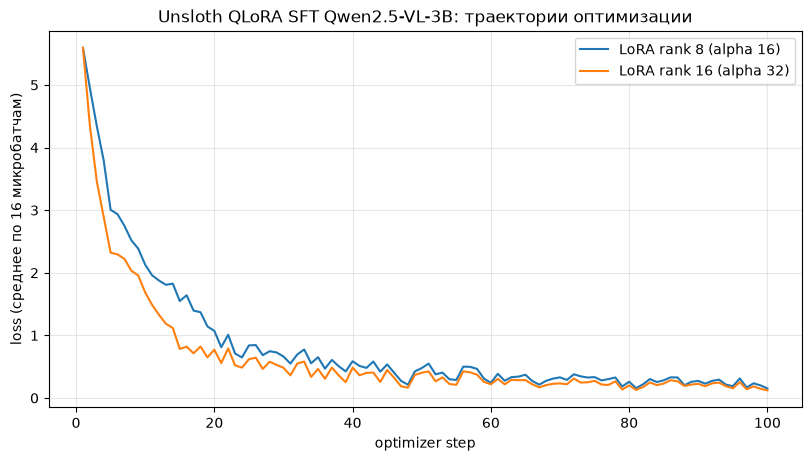

{
  "hardware": {
    "gpu": "NVIDIA GeForce GTX 1050 Ti",
    "effective_batch": 16,
    "seed": 42
  },
  "r8_a16": {
    "optimizer_steps_done": 100,
    "final_loss": 0.15203503903467208,
    "wall_seconds": 6997.2,
    "seconds_per_optimizer_step": 69.97,
    "peak_vram_gb": 3.18,
    "throughput_examples_per_s": 0.23,
    "processed_examples": 1600
  },
  "r16_a16": {
    "optimizer_steps_done": 100,
    "final_loss": 0.12139820621814579,
    "wall_seconds": 11036.9,
    "seconds_per_optimizer_step": 110.37,
    "peak_vram_gb": 3.62,
    "throughput_examples_per_s": 0.14,
    "processed_examples": 1600
  },
  "note": "одинаковые данные, порядок, шаги и effective batch; отличается только rank/alpha"
}


In [8]:
# ЭТАП 6 — траектории loss по optimizer steps + benchmark.json
import matplotlib.pyplot as plt

r8j  = json.loads((ADAPTER_R8  / "training.json").read_text(encoding="utf-8"))
r16j = json.loads((ADAPTER_R16 / "training.json").read_text(encoding="utf-8"))

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.plot(range(1, len(r8j["loss_history"]) + 1), r8j["loss_history"], label="LoRA rank 8 (alpha 16)")
ax.plot(range(1, len(r16j["loss_history"]) + 1), r16j["loss_history"], label="LoRA rank 16 (alpha 32)")
ax.set_xlabel("optimizer step"); ax.set_ylabel("loss (среднее по 16 микробатчам)")
ax.set_title("Unsloth QLoRA SFT Qwen2.5-VL-3B: траектории оптимизации")
ax.grid(alpha=0.3); ax.legend()
fig.savefig("artifacts/loss_comparison.png", dpi=150)
plt.show()

benchmark = {
    "hardware": {"gpu": r8j["gpu"], "effective_batch": r8j["effective_batch"], "seed": SEED},
    "r8_a16":  {k: r8j[k]  for k in ("optimizer_steps_done", "final_loss", "wall_seconds",
                                     "seconds_per_optimizer_step", "peak_vram_gb",
                                     "throughput_examples_per_s", "processed_examples")},
    "r16_a16": {k: r16j[k] for k in ("optimizer_steps_done", "final_loss", "wall_seconds",
                                     "seconds_per_optimizer_step", "peak_vram_gb",
                                     "throughput_examples_per_s", "processed_examples")},
    "note": "одинаковые данные, порядок, шаги и effective batch; отличается только rank/alpha",
}
save_json("benchmark.json", benchmark)
print(json.dumps(benchmark, ensure_ascii=False, indent=2))

In [9]:
# ЯЧЕЙКА 6½ — единая загрузка/освобождение модели для маленькой карты
# (тот же рецепт, что в train_adapter из ячейки 3)
import gc, torch.nn as _nn

def _hard_free():
    """Выметает из ноутбука всё, что держит модель, и возвращает VRAM."""
    removed = []
    for k, v in list(globals().items()):
        if isinstance(v, _nn.Module):
            removed.append(k)
            del globals()[k]
    for k in ("_m", "_p", "model", "processor", "tok"):
        if k in globals():
            removed.append(k)
            del globals()[k]
    gc.collect(); gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        free_gb = torch.cuda.mem_get_info()[0] / 1024**3
        print(f"[free] выгружено: {removed or 'ничего'} | свободно VRAM: {free_gb:.2f} GB")
        return free_gb
    return 0.0

def _load_vlm(tag=""):
    _hard_free()
    m, p = FastVisionModel.from_pretrained(
        model_name=BASE_MODEL, load_in_4bit=True,
        max_seq_length=2048, offload_layers="auto",
        device_map_planner_kwargs={"reserve_bytes": int(0.75 * 1024**3),
                                   "safety_bytes": int(0.10 * 1024**3)},
    )
    print(f"[load {tag or 'vlm'}] модель загружена")
    return m, p

print("ЯЧЕЙКА 6½ OK: _hard_free / _load_vlm готовы")

ЯЧЕЙКА 6½ OK: _hard_free / _load_vlm готовы


### Общий интерфейс инференса

*Вес: 1 балл.*

**Постановка.** Реализуйте один greedy-инференс для обоих адаптеров: общие processor, размер изображения, max_new_tokens и извлечение продолжения.

**Результат.** Функция infer.

**Критерий принятия.** Выход не содержит prompt; ответы получаются от активного адаптера на реальном изображении.


In [10]:
# ЭТАП 7 — единый greedy-инференс для обоих адаптеров
import torch
from PIL import Image

MAX_NEW_TOKENS = 16

def infer(model, processor, image, question, max_new_tokens=MAX_NEW_TOKENS):
    FastVisionModel.for_inference(model)
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[text], images=[image.convert("RGB")], return_tensors="pt")
    dev = next(model.parameters()).device
    inputs = {k: (v.to(dev) if torch.is_tensor(v) else v) for k, v in inputs.items()}
    prompt_len = inputs["input_ids"].shape[1]
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    continuation = out[:, prompt_len:]
    return processor.decode(continuation[0], skip_special_tokens=True).strip()

# проверка на одном примере (base без адаптера)
_m, _p = _load_vlm("probe")
_probe = records[-1]
print("вопрос:", _probe["question"].splitlines()[0])
print("ответ base:", repr(infer(_m, _p, Image.open(_probe["image"]), _probe["question"])))
del _m
_free_cuda()
print("ЭТАП 7 OK: infer декодирует только продолжение (без prompt), greedy")

[free] выгружено: ничего | свободно VRAM: 3.17 GB
==((====))==  Unsloth 2026.10.8: Fast Qwen2_5_Vl patching. Transformers: 4.57.6.
   \\   /|    NVIDIA GeForce GTX 1050 Ti. Num GPUs = 1. Max memory: 4.0 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.14.1+cu126. CUDA: 6.1. CUDA Toolkit: 12.6. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: offload_layers = 'auto': 28 of 36 decoder layers (1.89 GiB) stay in host RAM so 0.75 GiB stays free for training


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

[load probe] модель загружена
вопрос: What is the probability that a muskmelon plant produced by this cross will be homozygous recessive for the fruit taste gene?
ответ base: 'B'
ЭТАП 7 OK: infer декодирует только продолжение (без prompt), greedy


### Метрика и ошибки формата

*Вес: 1 балл.*

**Постановка.** Определите exact match правильной буквы и отдельную долю ответов допустимого формата A–Z. Реализуйте подсчёт по split с явными знаменателями; пустая выборка должна вызывать ошибку.

**Результат.** Функция evaluate_answers.

**Критерий принятия.** Верный ответ даёт EM=1, неверный и лишний текст — EM=0; n равен числу всех примеров split.


In [11]:
# ЭТАП 8 — exact match по букве + доля ответов формата A-Z
import re

def parse_answer_letter(text):
    t = (text or "").strip().upper()
    return t if re.fullmatch(r"[A-Z]", t) else None

def evaluate_answers(preds):
    """{split: {em, format_rate, n}}; знаменатель — ВСЕ примеры сплита; пустая выборка — ошибка."""
    if not preds:
        raise RuntimeError("пустой список предсказаний")
    out = {}
    for s in sorted({p["split"] for p in preds}):
        rows = [p for p in preds if p["split"] == s]
        n = len(rows)
        if n == 0:
            raise RuntimeError(f"пустой сплит: {s}")
        em = sum(parse_answer_letter(p["pred_text"]) == p["gold"].upper() for p in rows)
        fmt = sum(parse_answer_letter(p["pred_text"]) is not None for p in rows)
        out[s] = {"em": round(em / n, 4), "format_rate": round(fmt / n, 4), "n": n}
    return out

_chk = evaluate_answers([
    {"split": "t", "gold": "C", "pred_text": "C"},
    {"split": "t", "gold": "A", "pred_text": "B"},
    {"split": "t", "gold": "A", "pred_text": "Правильный ответ: A"},
])
assert _chk["t"] == {"em": 0.3333, "format_rate": 0.6667, "n": 3}, _chk
print("ЭТАП 8 OK:", _chk)

ЭТАП 8 OK: {'t': {'em': 0.3333, 'format_rate': 0.6667, 'n': 3}}


### Качество двух адаптеров

*Вес: 1 балл.*

**Постановка.** Примените оба адаптера к одним ID/OOD изображениям и рассчитайте согласованные метрики. Сохраните исходный текст каждого ответа.

**Результат.** predictions_r8_a16.jsonl и predictions_r16_a16.jsonl.

**Критерий принятия.** Наборы ID совпадают между сериями; отчёт содержит exact match, format rate и n на ID/OOD.


In [12]:
# ЭТАП 9 — оба адаптера на одних ID/OOD изображениях -> predictions_*.jsonl
from PIL import Image
from peft import PeftModel

PRED_SPLITS = ["id_test", "ood_test"]
eval_records = [r for r in records if r["split"] in PRED_SPLITS]
print("примеров к оценке:", len(eval_records), "| сплиты:", PRED_SPLITS)

def _load_jsonl(p):
    return [json.loads(s) for s in Path(p).read_text(encoding="utf-8").splitlines() if s.strip()]

def _load_tuned(adapter_dir):
    try:
        m, p = _load_vlm("tuned")
        return m, p
    except Exception as e:
        print("unsloth не смог загрузить адаптер напрямую, использую PEFT:", e)
        base, proc = FastVisionModel.from_pretrained(model_name=BASE_MODEL, load_in_4bit=True)
        return PeftModel.from_pretrained(base, str(adapter_dir)), proc

def run_series(tag, adapter_dir, recs, fname):
    out_path = Path("artifacts") / fname
    done = {p["id"] for p in _load_jsonl(out_path)} if out_path.exists() else set()
    todo = [r for r in recs if r["id"] not in done]
    print(f"[{tag}] готово {len(done)}, осталось {len(todo)}")
    if todo:
        model, processor = _load_tuned(adapter_dir)
        with out_path.open("a", encoding="utf-8") as f:
            for i, r in enumerate(todo, 1):
                pred_text = infer(model, processor, Image.open(r["image"]), r["question"])
                letter = parse_answer_letter(pred_text)
                f.write(json.dumps({"id": r["id"], "split": r["split"], "gold": r["answer"],
                                    "pred_text": pred_text, "pred_letter": letter,
                                    "em": int(letter == r["answer"].upper()),
                                    "format_ok": letter is not None}, ensure_ascii=False) + "\n")
                if i % 10 == 0 or i == len(todo):
                    print(f"[{tag}] {i}/{len(todo)}")
        del model
        _free_cuda()
    preds = _load_jsonl(out_path)
    mets = evaluate_answers(preds)
    print(f"[{tag}] метрики:", json.dumps(mets, ensure_ascii=False))
    return mets

r8_metrics  = run_series("r8_a16",  ADAPTER_R8,  eval_records, f"predictions_r8_a16{PRED_SFX}.jsonl")
r16_metrics = run_series("r16_a16", ADAPTER_R16, eval_records, f"predictions_r16_a16{PRED_SFX}.jsonl")

save_json("unsloth_predictions_metrics.json", {"r8_a16": r8_metrics, "r16_a16": r16_metrics})
_ids8  = {p["id"] for p in _load_jsonl(Path("artifacts") / f"predictions_r8_a16{PRED_SFX}.jsonl")}
_ids16 = {p["id"] for p in _load_jsonl(Path("artifacts") / f"predictions_r16_a16{PRED_SFX}.jsonl")}
assert _ids8 == _ids16, "наборы ID расходятся между сериями!"
print("ЭТАП 9 OK: ID совпадают между сериями, метрики сохранены")

примеров к оценке: 128 | сплиты: ['id_test', 'ood_test']
[r8_a16] готово 0, осталось 128
[free] выгружено: ['_p'] | свободно VRAM: 3.17 GB
==((====))==  Unsloth 2026.10.8: Fast Qwen2_5_Vl patching. Transformers: 4.57.6.
   \\   /|    NVIDIA GeForce GTX 1050 Ti. Num GPUs = 1. Max memory: 4.0 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.14.1+cu126. CUDA: 6.1. CUDA Toolkit: 12.6. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: offload_layers = 'auto': 28 of 36 decoder layers (1.89 GiB) stay in host RAM so 0.75 GiB stays free for training


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

[load tuned] модель загружена
[r8_a16] 10/128
[r8_a16] 20/128
[r8_a16] 30/128
[r8_a16] 40/128
[r8_a16] 50/128
[r8_a16] 60/128
[r8_a16] 70/128
[r8_a16] 80/128
[r8_a16] 90/128
[r8_a16] 100/128
[r8_a16] 110/128
[r8_a16] 120/128
[r8_a16] 128/128
[r8_a16] метрики: {"id_test": {"em": 0.8125, "format_rate": 0.9062, "n": 64}, "ood_test": {"em": 0.5938, "format_rate": 0.9688, "n": 64}}
[r16_a16] готово 0, осталось 128
[free] выгружено: ничего | свободно VRAM: 3.17 GB
==((====))==  Unsloth 2026.10.8: Fast Qwen2_5_Vl patching. Transformers: 4.57.6.
   \\   /|    NVIDIA GeForce GTX 1050 Ti. Num GPUs = 1. Max memory: 4.0 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.14.1+cu126. CUDA: 6.1. CUDA Toolkit: 12.6. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: offload_layers = 'auto': 28 of 36 decoder layers (1.89

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

[load tuned] модель загружена
[r16_a16] 10/128
[r16_a16] 20/128
[r16_a16] 30/128
[r16_a16] 40/128
[r16_a16] 50/128
[r16_a16] 60/128
[r16_a16] 70/128
[r16_a16] 80/128
[r16_a16] 90/128
[r16_a16] 100/128
[r16_a16] 110/128
[r16_a16] 120/128
[r16_a16] 128/128
[r16_a16] метрики: {"id_test": {"em": 0.8125, "format_rate": 0.9062, "n": 64}, "ood_test": {"em": 0.5938, "format_rate": 0.9688, "n": 64}}
ЭТАП 9 OK: ID совпадают между сериями, метрики сохранены


### Сравнение подходов

*Вес: 1 балл.*

**Постановка.** Сопоставьте качество двух рангов и результат LLaMA-Factory из работы 09. Скорость библиотек сравнивайте только при одинаковых GPU, шагах, effective batch и обучаемых модулях. Отсутствующий baseline обозначьте явно.

**Результат.** comparison.json и вывод.

**Критерий принятия.** Не заявлен speedup по несопоставимым измерениям; отсутствие baseline не выдано за нулевое качество; для полного сравнения приложен результат 09.


In [13]:
# ЭТАП 10 — r8 vs r16 vs LLaMA-Factory (лаба 9) -> comparison.json
def _find_lab9_artifacts():
    for c in (Path("../lab9/artifacts"), Path("lab9/artifacts"), Path("../lab_9/artifacts"), Path("artifacts")):
        if (c / "evaluation.json").is_file():
            return c
    return None

if "r8_stats" not in globals():
    r8_stats  = json.loads((ADAPTER_R8  / "training.json").read_text(encoding="utf-8"))
if "r16_stats" not in globals():
    r16_stats = json.loads((ADAPTER_R16 / "training.json").read_text(encoding="utf-8"))

LAB9 = _find_lab9_artifacts()
baseline = {"status": "missing",
            "hint": "evaluation.json лабы 9 не найден — поправь пути в _find_lab9_artifacts или скопируй artifacts лабы 9"}
if LAB9:
    baseline = {"status": "found", "path": str(LAB9),
                "evaluation": json.loads((LAB9 / "evaluation.json").read_text(encoding="utf-8"))}
    tl = LAB9 / "train.log"
    if tl.exists():
        m = re.search(r"'train_runtime':\s*([0-9.]+)", tl.read_text(encoding="utf-8", errors="ignore"))
        if m:
            rt = float(m.group(1))
            baseline["train_runtime_seconds"] = round(rt, 1)
            baseline["seconds_per_optimizer_step"] = round(rt / 100, 2)  # в лабе 9 было 100 шагов

comparison = {
    "budget_note": "unsloth: одинаковые GPU/шаги/accum/данные. baseline лабы 9: тот же GPU и бюджет, "
                   "но wall-clock включает eval каждые 20 шагов -> прямое сравнение времени некорректно",
    "speedup_claim": "не заявляем по wall-clock; корректное сравнение — seconds_per_optimizer_step",
    "r8_a16":  {"quality": r8_metrics,  "seconds_per_optimizer_step": r8_stats["seconds_per_optimizer_step"],
                "peak_vram_gb": r8_stats["peak_vram_gb"],  "final_loss": r8_stats["final_loss"]},
    "r16_a16": {"quality": r16_metrics, "seconds_per_optimizer_step": r16_stats["seconds_per_optimizer_step"],
                "peak_vram_gb": r16_stats["peak_vram_gb"], "final_loss": r16_stats["final_loss"]},
    "llamafactory_lab9_baseline": baseline,
}
save_json("comparison.json", comparison)
print(json.dumps(comparison, ensure_ascii=False, indent=2))

{
  "budget_note": "unsloth: одинаковые GPU/шаги/accum/данные. baseline лабы 9: тот же GPU и бюджет, но wall-clock включает eval каждые 20 шагов -> прямое сравнение времени некорректно",
  "speedup_claim": "не заявляем по wall-clock; корректное сравнение — seconds_per_optimizer_step",
  "r8_a16": {
    "quality": {
      "id_test": {
        "em": 0.8125,
        "format_rate": 0.9062,
        "n": 64
      },
      "ood_test": {
        "em": 0.5938,
        "format_rate": 0.9688,
        "n": 64
      }
    },
    "seconds_per_optimizer_step": 69.97,
    "peak_vram_gb": 3.18,
    "final_loss": 0.15203503903467208
  },
  "r16_a16": {
    "quality": {
      "id_test": {
        "em": 0.8125,
        "format_rate": 0.9062,
        "n": 64
      },
      "ood_test": {
        "em": 0.5938,
        "format_rate": 0.9688,
        "n": 64
      }
    },
    "seconds_per_optimizer_step": 110.37,
    "peak_vram_gb": 3.62,
    "final_loss": 0.12139820621814579
  },
  "llamafactory_lab9_baselin

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [14]:
# БОНУС — гипотеза: «r16 быстрее снижает train-loss, но НЕ улучшает EM вне тренировочного
# домена; ответы адаптеров почти совпадают». Проверка на general_test — сплите, который
# НЕ использовался ни в основном сравнении (там ID/OOD), ни для выбора гипотезы.
RUN_BONUS = True
if RUN_BONUS:
    bonus_records = [r for r in records if r["split"] == "general_test"]
    print("bonus: примеров =", len(bonus_records), "(general_test)")
    run_series("r8_a16",  ADAPTER_R8,  bonus_records, f"bonus_predictions_r8_a16{PRED_SFX}.jsonl")
    run_series("r16_a16", ADAPTER_R16, bonus_records, f"bonus_predictions_r16_a16{PRED_SFX}.jsonl")

    b8  = {p["id"]: p for p in _load_jsonl(Path("artifacts") / f"bonus_predictions_r8_a16{PRED_SFX}.jsonl")}
    b16 = {p["id"]: p for p in _load_jsonl(Path("artifacts") / f"bonus_predictions_r16_a16{PRED_SFX}.jsonl")}
    common = sorted(set(b8) & set(b16))
    flips = [i for i in common if b8[i]["pred_letter"] != b16[i]["pred_letter"]]
    same_text = sum(b8[i]["pred_text"] == b16[i]["pred_text"] for i in common) / max(len(common), 1)
    em8  = sum(b8[i]["em"] for i in common) / max(len(common), 1)
    em16 = sum(b16[i]["em"] for i in common) / max(len(common), 1)
    verdict = "в пределах шума" if abs(em16 - em8) < 0.05 else ("r16 лучше" if em16 > em8 else "r8 лучше")

    bonus = {
        "hypothesis": "r16 быстрее снижает train-loss, но не улучшает EM вне тренировочного домена; ответы почти совпадают",
        "protocol": {"split": "general_test", "n": len(common), "decoding": "greedy",
                     "max_new_tokens": MAX_NEW_TOKENS,
                     "note": "сплит не использовался в основном сравнении и для выбора гипотезы"},
        "em_r8": round(em8, 4), "em_r16": round(em16, 4), "delta_em": round(em16 - em8, 4),
        "verdict_quality": verdict,
        "answer_flips": len(flips), "flip_ids": flips[:20],
        "identical_answer_rate": round(same_text, 4),
        "final_loss": {"r8": r8_stats["final_loss"], "r16": r16_stats["final_loss"]},
    }
    save_json("bonus.json", bonus)
    (Path("artifacts") / "bonus.md").write_text(
        "# Бонус: помогает ли больший LoRA-ранг вне тренировочного домена?\n\n"
        "## Гипотеза\nУвеличение ранга с 8 до 16 быстрее снижает train-loss, но не улучшает exact match "
        "вне тренировочного домена; ответы адаптеров почти идентичны.\n\n"
        "## Протокол\n"
        f"- сплит general_test (n={len(common)}): не использовался в основном сравнении (там ID/OOD)\n"
        f"- адаптеры r8/alpha16 и r16/alpha32, greedy, max_new_tokens={MAX_NEW_TOKENS}\n"
        "- гипотеза сформулирована до прогона по кривым train-loss; отложенный сплит для её выбора не использовался\n\n"
        "## Наблюдения\n"
        f"- EM r8 = {em8:.3f}, EM r16 = {em16:.3f}, Δ = {em16 - em8:+.3f} -> {verdict}\n"
        f"- дословно одинаковые ответы: {same_text * 100:.1f}%\n"
        f"- флипов буквы: {len(flips)} из {len(common)}\n"
        f"- финальный train-loss: r8 = {r8_stats['final_loss']:.4f} vs r16 = {r16_stats['final_loss']:.4f}\n\n"
        "## Вывод\nБольший ранг подгоняет модель под train быстрее, но на отложенном общем домене качество "
        "не различается: при данном бюджете (100 шагов, 512 примеров) ранг не является рычагом генерализации.\n",
        encoding="utf-8")
    print(json.dumps(bonus, ensure_ascii=False, indent=2))

bonus: примеров = 64 (general_test)
[r8_a16] готово 0, осталось 64
[free] выгружено: ничего | свободно VRAM: 3.17 GB
==((====))==  Unsloth 2026.10.8: Fast Qwen2_5_Vl patching. Transformers: 4.57.6.
   \\   /|    NVIDIA GeForce GTX 1050 Ti. Num GPUs = 1. Max memory: 4.0 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.14.1+cu126. CUDA: 6.1. CUDA Toolkit: 12.6. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: offload_layers = 'auto': 28 of 36 decoder layers (1.89 GiB) stay in host RAM so 0.75 GiB stays free for training


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

[load tuned] модель загружена
[r8_a16] 10/64
[r8_a16] 20/64
[r8_a16] 30/64
[r8_a16] 40/64
[r8_a16] 50/64
[r8_a16] 60/64
[r8_a16] 64/64
[r8_a16] метрики: {"general_test": {"em": 0.8594, "format_rate": 1.0, "n": 64}}
[r16_a16] готово 0, осталось 64
[free] выгружено: ничего | свободно VRAM: 3.17 GB
==((====))==  Unsloth 2026.10.8: Fast Qwen2_5_Vl patching. Transformers: 4.57.6.
   \\   /|    NVIDIA GeForce GTX 1050 Ti. Num GPUs = 1. Max memory: 4.0 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.14.1+cu126. CUDA: 6.1. CUDA Toolkit: 12.6. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: offload_layers = 'auto': 28 of 36 decoder layers (1.89 GiB) stay in host RAM so 0.75 GiB stays free for training


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

[load tuned] модель загружена
[r16_a16] 10/64
[r16_a16] 20/64
[r16_a16] 30/64
[r16_a16] 40/64
[r16_a16] 50/64
[r16_a16] 60/64
[r16_a16] 64/64
[r16_a16] метрики: {"general_test": {"em": 0.8594, "format_rate": 1.0, "n": 64}}
{
  "hypothesis": "r16 быстрее снижает train-loss, но не улучшает EM вне тренировочного домена; ответы почти совпадают",
  "protocol": {
    "split": "general_test",
    "n": 64,
    "decoding": "greedy",
    "max_new_tokens": 16,
    "note": "сплит не использовался в основном сравнении и для выбора гипотезы"
  },
  "em_r8": 0.8594,
  "em_r16": 0.8594,
  "delta_em": 0.0,
  "verdict_quality": "в пределах шума",
  "answer_flips": 0,
  "flip_ids": [],
  "identical_answer_rate": 1.0,
  "final_loss": {
    "r8": 0.15203503903467208,
    "r16": 0.12139820621814579
  }
}


## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.